# Internal Covariate Shift: What It Is, How to Measure It, and What It Does (and Doesn't) Explain

**Covariate shift** means the distribution of a model's *inputs* changes between training and use. **Internal covariate shift (ICS)** is the claim that the same thing happens *inside* a deep network during training: layer `k` receives its input from layers `1..k-1`, and every time those earlier layers' weights are updated, the distribution of layer `k`'s input changes. Layer `k` is trying to learn on a moving target.

```
 x --> [Layer 1] --> h1 --> [Layer 2] --> h2 --> [Layer 3] --> h3 --> ... --> loss
          ^                    ^                    ^
      updated each         input distribution   input distribution
      step                 of layer 2 moves     of layer 3 moves
                           because layer 1      because layers 1-2
                           changed              changed
```

Batch Normalization (Ioffe & Szegedy, 2015) was introduced as a way to reduce ICS by re-standardizing each layer's inputs. Later work (Santurkar et al., 2018, *How Does Batch Normalization Help Optimization?*) challenged that explanation. This notebook lets you **see ICS, measure it, and test the explanation yourself**.

**What you will do**

1. Build a deep `tanh` network with and without BatchNorm, and a third variant with BatchNorm plus **deliberately injected** distribution shift
2. Watch each layer's input distribution drift during training
3. Measure ICS with a **gradient-based definition** (how much does layer `k`'s gradient change because earlier layers updated?)
4. Compare training speed and stability across learning rates
5. Test the key question: if ICS is what BatchNorm fixes, then injecting ICS back in should destroy BatchNorm's benefit. Does it?
6. Measure how smooth the loss landscape is, the alternative explanation

All results come from small experiments on one dataset, so treat them as illustrations, not proofs.

## 0. Setup

In [1]:
import copy
import math
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)   # tiny networks run faster single-threaded on CPU
device = torch.device("cpu")   # small enough that the CPU is fastest and measurements stay simple
print("torch", torch.__version__)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

torch 2.15.0+cu132


## 1. Data and the three networks

Data: scikit-learn's handwritten **digits** (8x8 images, 10 classes): 1000 train, 400 validation, the rest test.

We compare three deep MLPs (8 hidden layers of 64 units, `tanh` activations):

| Name | Each hidden block | Purpose |
|---|---|---|
| **plain** | `Linear -> tanh` | the baseline |
| **BN** | `Linear -> BatchNorm -> tanh` | standard BatchNorm |
| **BN + mild noise** | `Linear -> BatchNorm -> Noise -> tanh` | BatchNorm, then **random per-unit scale and shift, resampled every training step** (shift std 0.3, log-scale std 0.15). This deliberately creates distribution shift *after* the normalization, so the next layer sees a moving input again |
| **BN + strong noise** | same | the same idea with much larger noise (shift std 1.0, log-scale std 0.5) |

Having two noise levels matters: the question "does injected shift hurt?" turns out to depend on *how much* shift you inject.

All three use the same careful initialization (Xavier with the `tanh` gain), so the plain network is a fair baseline and not one that fails just because of a bad init. The noise layer is only active in training mode.

In [2]:
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
yd = digits.target.astype(np.int64)

X_tr, X_rest, y_tr, y_rest = train_test_split(Xd, yd, train_size=1000, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=400, stratify=y_rest, random_state=SEED)
print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}")

# a fixed batch we use to *observe* the network without affecting training
PROBE_X = torch.tensor(X_tr[:256]); PROBE_Y = torch.tensor(y_tr[:256])

train=1000  val=400  test=397


In [3]:
class NoisyAffine(nn.Module):
    """Training only: per-unit random scale and shift, resampled on every forward pass and
    shared by every sample in the batch, so the layer's input distribution jumps between steps."""
    def __init__(self, shift_std=1.0, log_scale_std=0.5):
        super().__init__()
        self.shift_std, self.log_scale_std = shift_std, log_scale_std

    def forward(self, x):
        if not self.training:
            return x
        shift = torch.randn(1, x.shape[1]) * self.shift_std
        scale = torch.exp(torch.randn(1, x.shape[1]) * self.log_scale_std)
        return x * scale + shift


class DeepMLP(nn.Module):
    def __init__(self, norm="none", depth=8, width=64, in_dim=64, out_dim=10, shift_std=0.0, log_scale_std=0.0):
        super().__init__()
        blocks, d = [], in_dim
        for _ in range(depth):
            layers = [nn.Linear(d, width)]
            if norm in ("bn", "bn_noise"):
                layers.append(nn.BatchNorm1d(width))
            if norm == "bn_noise":
                layers.append(NoisyAffine(shift_std, log_scale_std))
            layers.append(nn.Tanh())
            blocks.append(nn.Sequential(*layers))
            d = width
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Linear(width, out_dim)
        gain = nn.init.calculate_gain("tanh")
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight, gain=gain if m is not self.head else 1.0)
                nn.init.zeros_(m.bias)

    def forward(self, x, return_acts=False):
        acts = []
        for b in self.blocks:
            acts.append(x)              # acts[j] = the INPUT of layer j
            x = b(x)
        acts.append(x)                  # input of the output layer
        out = self.head(x)
        return (out, acts) if return_acts else out

    def layer_modules(self):
        return list(self.blocks) + [self.head]


# name -> (normalization, noise shift std, noise log-scale std)
NORMS = {
    "plain":             ("none", 0.0, 0.0),
    "BN":                ("bn", 0.0, 0.0),
    "BN + mild noise":   ("bn_noise", 0.3, 0.15),
    "BN + strong noise": ("bn_noise", 1.0, 0.5),
}


def new_model(name, seed=SEED):
    set_seed(seed)
    norm, shift_std, log_scale_std = NORMS[name]
    return DeepMLP(norm=norm, shift_std=shift_std, log_scale_std=log_scale_std)


loss_fn = nn.CrossEntropyLoss()
print({k: sum(p.numel() for p in new_model(k).parameters()) for k in NORMS}, "parameters")

{'plain': 33930, 'BN': 34954, 'BN + mild noise': 34954, 'BN + strong noise': 34954} parameters


## 2. Training loop (with a hook for measurements)

The usual loop, plus an optional `callback(step, model, xb, yb)` that runs *before* each optimizer step. We use it to observe the network without touching the training itself: it only works on deep copies of the model and restores the random-number state, so a measured run trains identically to an unmeasured one.

In [4]:
def make_loader(X, y, batch_size=64, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y)), batch_size=batch_size, shuffle=shuffle)


val_loader = make_loader(X_va, y_va, batch_size=512)
test_loader = make_loader(X_te, y_te, batch_size=512)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total / n, correct / n


def fit(model, epochs=30, lr=0.05, momentum=0.9, batch_size=64, callback=None):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = make_loader(X_tr, y_tr, batch_size=batch_size, shuffle=True)
    h = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": []}
    step = 0
    for _ in range(epochs):
        model.train()
        ep_losses = []
        for xb, yb in loader:
            if callback is not None:
                callback(step, model, xb, yb)
            model.train()
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            h["step_loss"].append(loss.item()); ep_losses.append(loss.item()); step += 1
        vl, va = evaluate(model, val_loader)
        h["train_loss"].append(float(np.mean(ep_losses))); h["val_loss"].append(vl); h["val_acc"].append(va)
    return h

## 3. Two ways to measure internal covariate shift

**(a) Distribution drift.** Pick a fixed batch of data. At regular steps, push it through the network and record the **input to each layer**: its per-unit mean and standard deviation. If the stats move a lot between steps, that layer's input distribution is shifting.

**(b) The gradient-based ICS measure** (from Santurkar et al., 2018). The real worry behind ICS is not that distributions move, but that **the gradient layer `k` computed becomes stale** once earlier layers update. So for layer `k` at a given step:

1. `G` = gradient of the loss w.r.t. layer `k`'s weights at the current parameters
2. Apply one SGD step to layers **before** `k` only, then recompute the gradient of layer `k`'s weights on the same batch: `G'`
3. ICS for layer `k` = how different `G` and `G'` are

We report the **relative distance** `||G - G'|| / ||G||` and the **cosine similarity** between them. Both are scale-free, so models whose gradients have different magnitudes can be compared fairly. A cosine near 1 and a relative distance near 0 mean the earlier update barely changed what layer `k` should do (little ICS). Lower cosine and larger distance mean more ICS.

In [5]:
@torch.no_grad()
def probe_acts(model, X, seed):
    """Inputs to layers 1..depth (the last entry feeds the output layer) on a fixed batch.
    Works on a copy in train mode, with the same behaviour (batch statistics, noise) the network has
    during training, and does not disturb the RNG or BatchNorm running stats of the real model."""
    m = copy.deepcopy(model).train()
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        _, acts = m(X, return_acts=True)
    return acts[1:]


def _grads_by_layer(m, xb, yb, seed):
    m.train()
    with torch.random.fork_rng():
        torch.manual_seed(seed)              # same noise draw whenever we want a like-for-like comparison
        loss = loss_fn(m(xb), yb)
    groups = [list(l.parameters()) for l in m.layer_modules()]
    flat = [p for g in groups for p in g]
    gs = torch.autograd.grad(loss, flat)
    out, i = [], 0
    for g in groups:
        out.append(gs[i:i + len(g)]); i += len(g)
    return out


def gradient_ics(model, xb, yb, lr, seed):
    """Returns, for layers 1..depth, (relative L2 distance, cosine) between the gradient of that
    layer's weights before and after one SGD step on all EARLIER layers."""
    base = copy.deepcopy(model)
    G = _grads_by_layer(base, xb, yb, seed)
    res = []
    for k in range(1, len(G)):
        m2 = copy.deepcopy(model)
        with torch.no_grad():
            for j in range(k):
                for p, g in zip(m2.layer_modules()[j].parameters(), G[j]):
                    p -= lr * g
        G2 = _grads_by_layer(m2, xb, yb, seed)
        a, b = G[k][0].flatten(), G2[k][0].flatten()      # [0] is the layer's weight matrix
        res.append(((a - b).norm() / a.norm()).item())
        res[-1] = (res[-1], F.cosine_similarity(a, b, dim=0).item())
    return res

In [6]:
class Tracker:
    """Observes a run: activation stats, gradient ICS, histograms and parameter checkpoints."""
    def __init__(self, lr, act_every=5, ics_every=15, ckpt_every=25, max_step=300,
                 hist_layer=4, hist_steps=(0, 50, 150, 300)):
        self.lr, self.act_every, self.ics_every, self.ckpt_every = lr, act_every, ics_every, ckpt_every
        self.max_step, self.hist_layer, self.hist_steps = max_step, hist_layer, set(hist_steps)
        self.act_steps, self.mu, self.sd, self.ics_steps, self.ics = [], [], [], [], []
        self.hist, self.ckpts = {}, []

    def __call__(self, step, model, xb, yb):
        if step > self.max_step:
            return
        if step % self.act_every == 0:
            acts = probe_acts(model, PROBE_X, seed=step)
            self.act_steps.append(step)
            self.mu.append(np.stack([a.mean(0).numpy() for a in acts]))      # [layers, units]
            self.sd.append(np.stack([a.std(0).numpy() for a in acts]))
            if step in self.hist_steps:
                self.hist[step] = acts[self.hist_layer - 1].flatten().numpy()
        if step % self.ics_every == 0:
            self.ics_steps.append(step)
            self.ics.append(np.array(gradient_ics(model, xb, yb, self.lr, seed=1000 + step)))   # [layers, 2]
        if step % self.ckpt_every == 0:
            self.ckpts.append((step, copy.deepcopy(model.state_dict())))

    def arrays(self):
        return (np.array(self.act_steps), np.stack(self.mu), np.stack(self.sd),
                np.array(self.ics_steps), np.stack(self.ics))

## 4. Run the three networks, instrumented

Each network trains with SGD + momentum (`lr=0.05`) for 20 epochs (about 320 steps), while the tracker records the measurements for the first 300 steps. Same seed, same data order.

In [7]:
LR_OBS = 0.05
tracked, tracked_hist = {}, {}
for name in NORMS:
    model = new_model(name)
    tr = Tracker(lr=LR_OBS)
    tracked_hist[name] = fit(model, epochs=20, lr=LR_OBS, callback=tr)
    tracked[name] = (model, tr)
    print(f"{name:<18}: final val acc {tracked_hist[name]['val_acc'][-1]:.3f} | "
          f"final train loss {tracked_hist[name]['train_loss'][-1]:.3f} | "
          f"{len(tr.act_steps)} activation probes, {len(tr.ics_steps)} ICS measurements")

plain             : final val acc 0.935 | final train loss 0.023 | 61 activation probes, 21 ICS measurements


BN                : final val acc 0.985 | final train loss 0.009 | 61 activation probes, 21 ICS measurements


BN + mild noise   : final val acc 0.968 | final train loss 0.038 | 61 activation probes, 21 ICS measurements


BN + strong noise : final val acc 0.968 | final train loss 0.380 | 61 activation probes, 21 ICS measurements


### 4a. Watching a layer's input distribution move

Layer 4's input (a `tanh` output, so it lives in `[-1, 1]`), on the same fixed batch, at four moments in training. If the distribution is stable, the four curves lie on top of each other. If the layer sees a moving target, they differ.

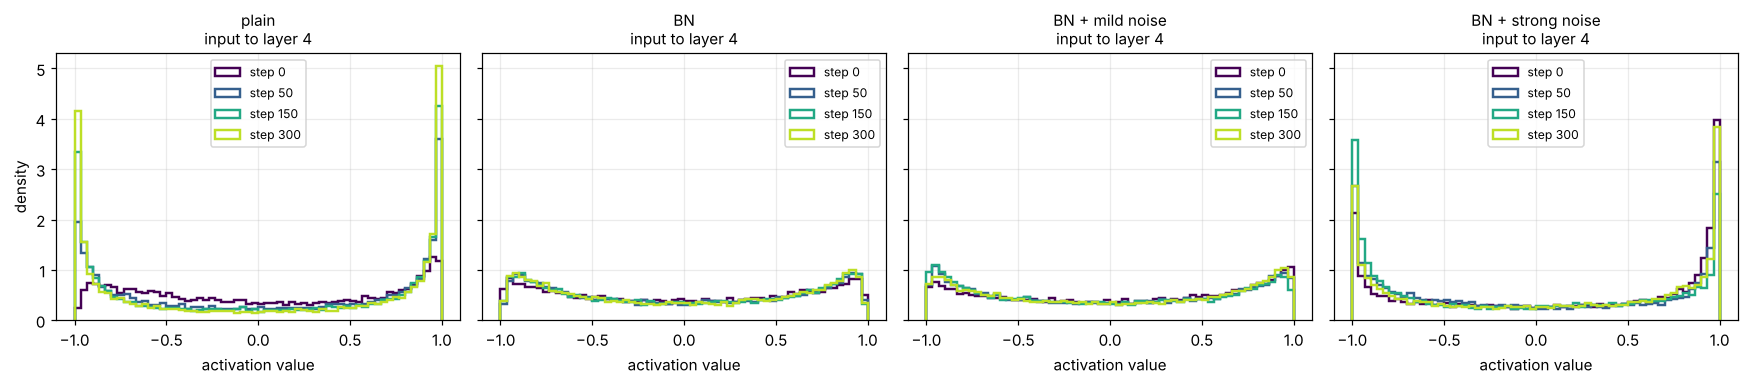

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, 4))
for ax, name in zip(axes, NORMS):
    tr = tracked[name][1]
    for c, (step, vals) in zip(colors, sorted(tr.hist.items())):
        ax.hist(vals, bins=60, range=(-1, 1), density=True, histtype="step", color=c, lw=1.6, label=f"step {step}")
    ax.set_title(f"{name}\ninput to layer {tr.hist_layer}", fontsize=10); ax.set_xlabel("activation value"); ax.legend(fontsize=8)
axes[0].set_ylabel("density")
plt.tight_layout(); plt.show()

**What to notice.** In the plain network the distribution is visibly moving: between step 0 and step 300 a lot of probability mass is pushed out to the `tanh` extremes at -1 and +1 (the units saturate). That is internal covariate shift in action: layer 4 is being trained on an input whose shape keeps changing. In the BatchNorm network the four curves almost coincide, and the mildly noisy BN network looks much the same. The strongly noisy network sits in between, with more mass at the edges and curves that do not quite line up.

One caution: this histogram pools every unit and every sample, so it can hide movement of individual units. The injected noise shifts each unit by a different random amount, and pooling averages much of that away. The next two views measure it per unit.

### 4b. Mean and spread of every layer's input over training

For each model: the average (across units) mean and standard deviation of each layer's input, over time. Flat lines mean a stable input distribution. Lines that wander mean that layer is seeing a changing input.

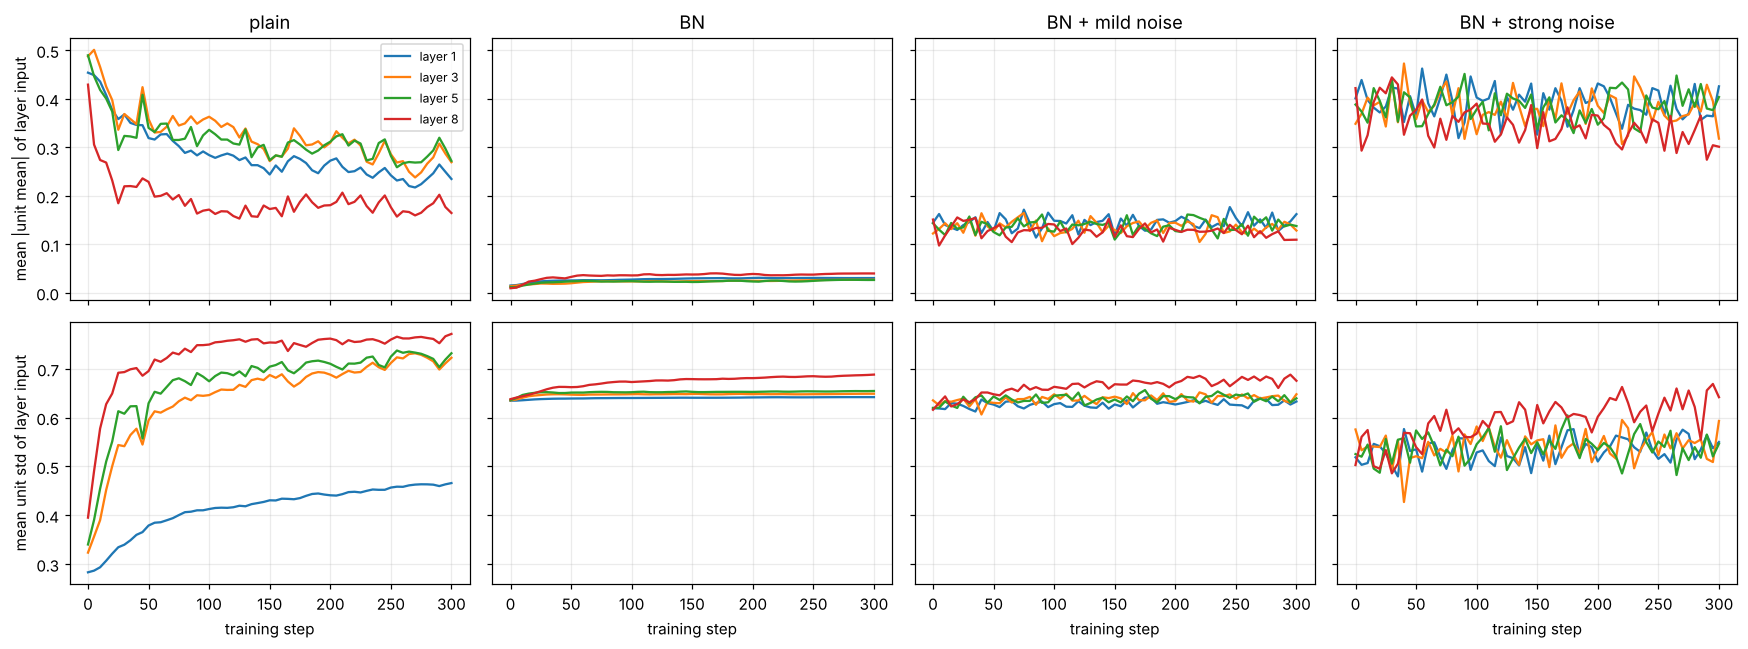

In [9]:
layer_sel = [1, 3, 5, 8]
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey='row')
for col, name in enumerate(NORMS):
    steps, mu, sd, _, _ = tracked[name][1].arrays()
    for L in layer_sel:
        axes[0, col].plot(steps, np.abs(mu[:, L - 1, :]).mean(1), label=f"layer {L}")
        axes[1, col].plot(steps, sd[:, L - 1, :].mean(1), label=f"layer {L}")
    axes[0, col].set_title(name); axes[1, col].set_xlabel("training step")
axes[0, 0].set_ylabel("mean |unit mean| of layer input"); axes[1, 0].set_ylabel("mean unit std of layer input")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice** (the y-axes are shared along each row, so the scales are directly comparable):

- **plain:** the layer inputs change *systematically* over the first 100 to 150 steps. Their mean magnitude falls from roughly 0.45 to 0.25, and their spread rises from roughly 0.3 to between 0.45 and 0.75, depending on the layer. The network is still reshaping its internal representation, so each layer has a changing input.
- **BN:** flat, close to zero mean and a nearly constant spread. Normalization pins these statistics, and the smooth changes that remain are tiny by comparison.
- **BN + noise:** the lines jitter from step to step around a constant level, because fresh random shifts are drawn every step. The jitter is small for mild noise and large for strong noise.

### 4c. Quantifying the drift

For each layer: how far, on average, does each unit's mean move between consecutive probes (5 steps apart), measured in units of that unit's typical spread? Bigger bars mean a more rapidly moving input distribution.

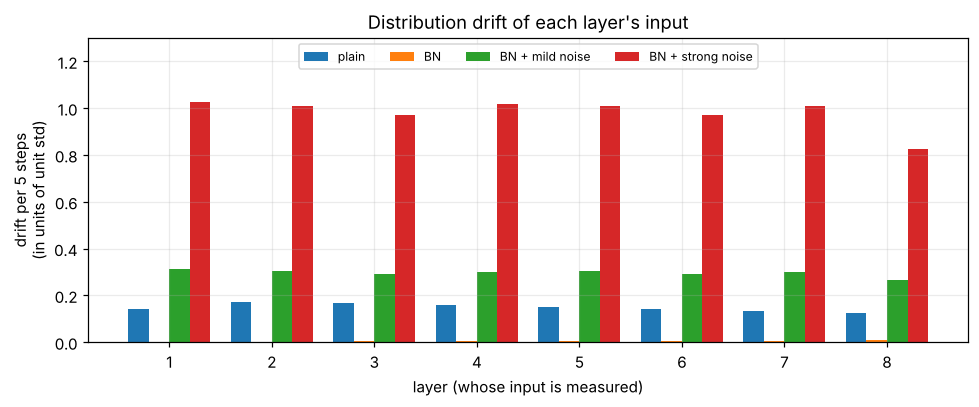

model              L1     L2     L3     L4     L5     L6     L7     L8      mean
plain              0.140  0.173  0.166  0.159  0.149  0.141  0.135  0.123   0.148
BN                 0.002  0.003  0.003  0.004  0.005  0.006  0.006  0.007   0.004
BN + mild noise    0.311  0.304  0.293  0.301  0.303  0.292  0.301  0.266   0.296
BN + strong noise  1.027  1.007  0.973  1.017  1.007  0.972  1.009  0.827   0.980


In [10]:
def drift_per_layer(tr):
    steps, mu, sd, _, _ = tr.arrays()
    sd_ref = sd.mean(0)                                         # typical spread of each unit over the run
    d = np.abs(np.diff(mu, axis=0)) / (sd_ref[None] + 1e-6)     # [probes-1, layers, units]
    return d.mean(axis=(0, 2))                                  # per layer


drifts = {name: drift_per_layer(tracked[name][1]) for name in NORMS}
layers = np.arange(1, 9)
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.2
for i, name in enumerate(NORMS):
    ax.bar(layers + (i - 1.5) * w, drifts[name], width=w, label=name)
ax.set_xlabel("layer (whose input is measured)"); ax.set_ylabel("drift per 5 steps\n(in units of unit std)")
ax.set_title("Distribution drift of each layer's input"); ax.set_ylim(0, 1.3); ax.legend(ncol=4, loc="upper center", fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'model':<18} " + " ".join(f"L{l:<5}" for l in layers) + "  mean")
for name, d in drifts.items():
    print(f"{name:<18} " + " ".join(f"{v:<6.3f}" for v in d) + f"  {d.mean():.3f}")

**What to notice.** Using the drift score (movement between probes, in units of each unit's typical spread), BatchNorm cuts the drift by roughly a factor of 35 relative to the plain network (about 0.004 vs 0.15). The two noise variants are the interesting part: mild noise has about **twice** the plain network's drift (about 0.30), and strong noise about **six and a half times** (about 0.98). We have manufactured networks whose layer inputs shift *more* than the plain network's do, which sets up the key test in section 5.

Note the different character of the shifts: the plain network's drift is a slow, systematic trend, whereas the injected drift is random jitter. This score counts both the same way.

### 4d. The gradient-based ICS measure

Averaged over the 300 observed steps. Left: relative distance between the gradient before and after earlier layers update (lower = less ICS). Right: cosine between them (higher = less ICS).

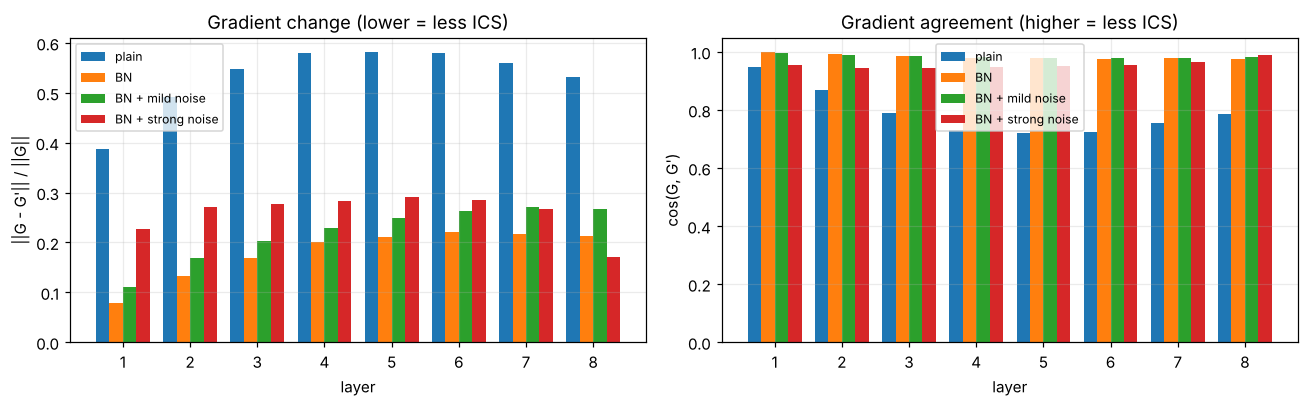

model               mean rel. distance  mean cosine
plain                            0.533        0.790
BN                               0.181        0.983
BN + mild noise                  0.220        0.984
BN + strong noise                0.259        0.956


In [11]:
ics_mean = {}
for name in NORMS:
    _, _, _, _, ics = tracked[name][1].arrays()
    ics_mean[name] = ics.mean(0)                 # [layers, (rel dist, cos)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for i, name in enumerate(NORMS):
    axes[0].bar(layers + (i - 1.5) * w, ics_mean[name][:, 0], width=w, label=name)
    axes[1].bar(layers + (i - 1.5) * w, ics_mean[name][:, 1], width=w, label=name)
axes[0].set_ylabel("||G - G'|| / ||G||"); axes[0].set_title("Gradient change (lower = less ICS)")
axes[1].set_ylabel("cos(G, G')"); axes[1].set_title("Gradient agreement (higher = less ICS)")
for ax in axes:
    ax.set_xlabel("layer"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'model':<18} {'mean rel. distance':>19} {'mean cosine':>12}")
for name in NORMS:
    print(f"{name:<18} {ics_mean[name][:, 0].mean():>19.3f} {ics_mean[name][:, 1].mean():>12.3f}")

**What to notice.** By this measure BatchNorm sharply reduces ICS: the relative gradient change falls from about 0.53 (plain) to about 0.18, and the cosine between the "before" and "after" gradients rises from about 0.79 to about 0.98. So an update to earlier layers leaves the gradient of a later layer much more intact in the BN network.

Look closely at the noisy variants, though. Their scores stay close to BN's (cosines of about 0.98 and 0.96), even though section 4c showed their distribution drift is far larger. This is not a bug. We compute the "after" gradient with the **same noise draw** as the "before" gradient, so this measure isolates the staleness caused by *earlier layers' updates* and ignores the injected noise, which is independent of the updates. The two measures are answering different questions. That is a general lesson: "internal covariate shift" has more than one operational definition, and they can disagree.

## 5. Does reducing ICS make training faster?

Now the performance question. For three learning rates, train each network (2 seeds, 30 epochs, SGD + momentum 0.9) and compare training loss and validation accuracy.

If ICS were the main obstacle, then the **noisy BN variants** (which have shift injected right back in, and which we measured as drifting more than the plain network) should lose BatchNorm's benefit and train like the plain network, not like BN.

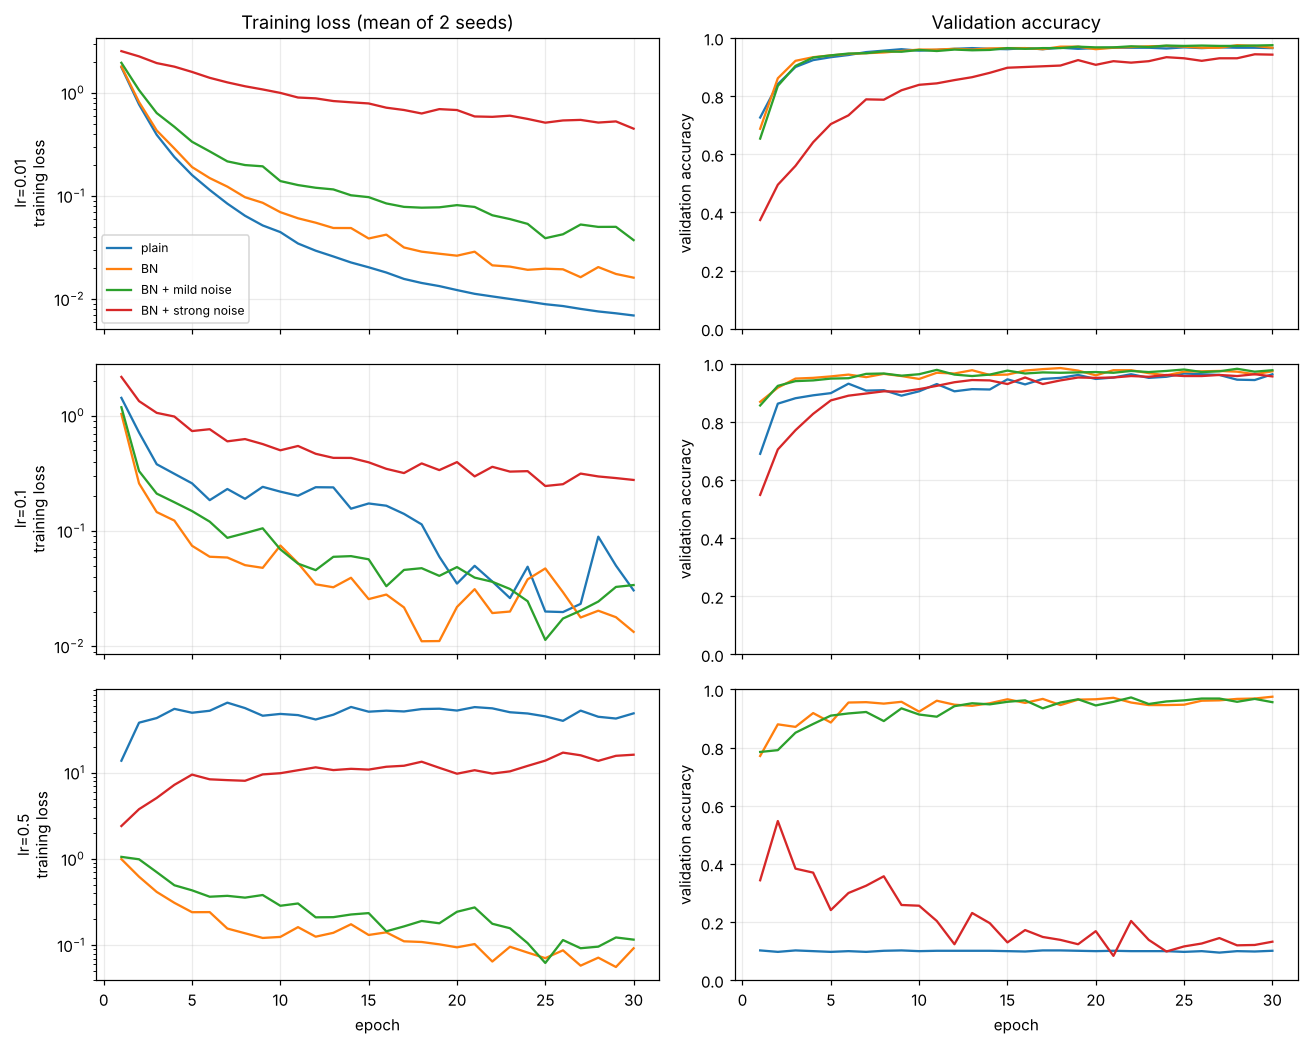

   lr model               final train loss  final val acc  epochs to 90% val
 0.01 plain                         0.0069          0.965                  3
 0.01 BN                            0.0162          0.966                  3
 0.01 BN + mild noise               0.0374          0.975                  3
 0.01 BN + strong noise             0.4508          0.943                 16
  0.1 plain                         0.0306          0.964                  6
  0.1 BN                            0.0134          0.974                  2
  0.1 BN + mild noise               0.0340          0.978                  2
  0.1 BN + strong noise             0.2772          0.956                  8
  0.5 plain                        48.8366          0.101               None
  0.5 BN                            0.0925          0.975                  4
  0.5 BN + mild noise               0.1164          0.956                  5
  0.5 BN + strong noise            16.1954          0.133               None

In [12]:
LRS = [0.01, 0.1, 0.5]
EPOCHS = 30
speed = {}
for lr in LRS:
    for name in NORMS:
        runs = [fit(new_model(name, seed=s), epochs=EPOCHS, lr=lr) for s in (0, 1)]
        speed[(lr, name)] = runs

fig, axes = plt.subplots(len(LRS), 2, figsize=(12, 3.2 * len(LRS)), sharex=True)
for r, lr in enumerate(LRS):
    for name in NORMS:
        runs = speed[(lr, name)]
        axes[r, 0].plot(range(1, EPOCHS + 1), np.mean([x["train_loss"] for x in runs], 0), label=name)
        axes[r, 1].plot(range(1, EPOCHS + 1), np.mean([x["val_acc"] for x in runs], 0), label=name)
    axes[r, 0].set_ylabel(f"lr={lr}\ntraining loss"); axes[r, 1].set_ylabel("validation accuracy")
    axes[r, 0].set_yscale("log"); axes[r, 1].set_ylim(0.0, 1.0)
axes[0, 0].legend(fontsize=8); axes[-1, 0].set_xlabel("epoch"); axes[-1, 1].set_xlabel("epoch")
axes[0, 0].set_title("Training loss (mean of 2 seeds)"); axes[0, 1].set_title("Validation accuracy")
plt.tight_layout(); plt.show()

def epochs_to(acc, runs):
    m = np.mean([x["val_acc"] for x in runs], 0)
    hit = np.where(m >= acc)[0]
    return int(hit[0]) + 1 if len(hit) else None

print(f"{'lr':>5} {'model':<18} {'final train loss':>17} {'final val acc':>14} {'epochs to 90% val':>18}")
for lr in LRS:
    for name in NORMS:
        runs = speed[(lr, name)]
        tl = np.mean([x["train_loss"][-1] for x in runs]); va = np.mean([x["val_acc"][-1] for x in runs])
        print(f"{lr:>5} {name:<18} {tl:>17.4f} {va:>14.3f} {str(epochs_to(0.90, runs)):>18}")

**What to notice.**

- **Small learning rate (0.01):** plain, BN and BN + mild noise all reach 90% validation accuracy in about 3 epochs, and the plain network even reaches the lowest training loss. BatchNorm is not faster here. (The noisy variants' training loss is measured with the noise switched on, so it is not directly comparable; validation accuracy is measured with it off.)
- **Medium learning rate (0.1):** BN and BN + mild noise reach 90% in 2 epochs, versus 6 for the plain network, and the plain network's training loss is much noisier.
- **Large learning rate (0.5):** the plain network **diverges** (loss around 49, accuracy 0.10, which is chance for 10 classes). BN trains normally (validation accuracy about 0.975), and so does **BN + mild noise** (about 0.956).
- **Strong noise** is a different story: it trains slowly at small rates and **fails at 0.5**, like the plain network.

The mild-noise result is the important one. That network has about twice the plain network's measured distribution drift (and about 70 times BN's), yet it behaves like BatchNorm: faster at 0.1, and stable at a learning rate where the plain network diverges. If BatchNorm helped mainly by reducing distribution drift, this network should have lost most of the benefit. It did not. That is consistent with Santurkar et al.'s finding that reducing ICS is not the main reason BatchNorm works.

The strong-noise result keeps the picture honest: **enough** injected shift does break training, so shift is not irrelevant. But that network is also being fed enormous random perturbations in the forward pass, which is more than "ICS" alone, so this does not show that natural ICS is harmful. The effect depends on the noise level (exercise 1).

*Caveats:* 2 seeds, one small dataset, one architecture, SGD with momentum.

## 6. The alternative explanation: a smoother loss landscape

Santurkar et al. argued that BatchNorm's real benefit is that it makes the **loss landscape smoother**: when you move along the gradient direction, the loss and the gradient change less abruptly, so the gradient is a more reliable guide and larger learning rates are safe.

We test this directly. At each checkpoint saved during training, we take **one plain gradient step with learning rate `a`** on a fixed batch, for a range of `a`, and record

- the **overshoot rate**: in how many checkpoints did the step make the loss go *up*? (a step too large for the local curvature overshoots)
- the **relative gradient change** `||g(after) - g(before)|| / ||g(before)||`: how stale the gradient became after moving, a scale-free measure of "gradient predictiveness"

The step size `a` is in the same units as a learning rate, so the question answered is the practical one: *if I used learning rate `a`, how badly would one step go wrong?*

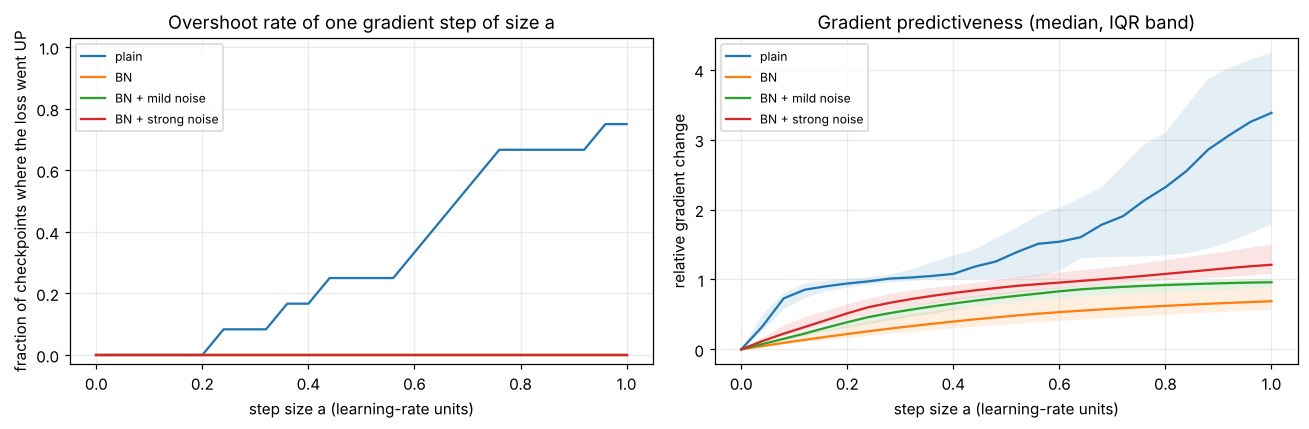

12 checkpoints (steps 25 to 300); columns are a = (0.1, 0.5, 1.0)
model                          overshoot rate      median rel. gradient change
plain                    0.00    0.25    0.75             0.85    1.26    3.38
BN                       0.00    0.00    0.00             0.14    0.46    0.69
BN + mild noise          0.00    0.00    0.00             0.23    0.73    0.96
BN + strong noise        0.00    0.00    0.00             0.32    0.88    1.21


In [13]:
ALPHAS = np.linspace(0.0, 1.0, 26)


def landscape(template, state, X, y, seed=123):
    m = copy.deepcopy(template); m.load_state_dict(state); m.train()
    params = list(m.parameters())

    def loss_grad():
        with torch.random.fork_rng():
            torch.manual_seed(seed)                  # identical noise draw for every evaluation
            loss = loss_fn(m(X), y)
        g = torch.autograd.grad(loss, params)
        return loss.item(), torch.cat([t.flatten() for t in g])

    L0, g0 = loss_grad()
    theta0 = [p.detach().clone() for p in params]
    dl, dg = [], []
    for a in ALPHAS:
        i = 0
        with torch.no_grad():
            for p, t in zip(params, theta0):
                n = p.numel()
                p.copy_(t - a * g0[i:i + n].view_as(p)); i += n
        L, g = loss_grad()
        dl.append(L - L0); dg.append(((g - g0).norm() / g0.norm()).item())
    return np.array(dl), np.array(dg)


land = {}
for name in NORMS:
    model, tr = tracked[name]
    curves = [landscape(model, st, PROBE_X, PROBE_Y) for step, st in tr.ckpts if step >= 25]
    land[name] = (np.stack([c[0] for c in curves]), np.stack([c[1] for c in curves]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in NORMS:
    dl, dg = land[name]
    axes[0].plot(ALPHAS, (dl > 1e-3).mean(0), label=name)
    med = np.median(dg, 0); lo, hi = np.percentile(dg, 25, 0), np.percentile(dg, 75, 0)
    axes[1].plot(ALPHAS, med, label=name); axes[1].fill_between(ALPHAS, lo, hi, alpha=0.12)
axes[0].set_ylabel("fraction of checkpoints where the loss went UP")
axes[0].set_title("Overshoot rate of one gradient step of size a"); axes[0].set_ylim(-0.03, 1.03)
axes[1].set_ylabel("relative gradient change"); axes[1].set_title("Gradient predictiveness (median, IQR band)")
for ax in axes:
    ax.set_xlabel("step size a (learning-rate units)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

n_ck = land["plain"][0].shape[0]
A = (0.1, 0.5, 1.0)
idx = [int(np.argmin(np.abs(ALPHAS - a))) for a in A]
print(f"{n_ck} checkpoints (steps 25 to 300); columns are a = {A}")
print(f"{'model':<18} {'overshoot rate':>26}   {'median rel. gradient change':>30}")
for name in NORMS:
    ov = [(land[name][0][:, i] > 1e-3).mean() for i in idx]
    gc = [np.median(land[name][1][:, i]) for i in idx]
    print(f"{name:<18} {'  '.join(f'{v:6.2f}' for v in ov):>26}   {'  '.join(f'{v:6.2f}' for v in gc):>30}")

**What to notice.** The right panel is the cleaner one. After a step of the same size, the gradient of the plain network has changed by far more than that of any BatchNorm variant. At `a = 0.1` the median relative change is about 0.85 for the plain network, against about 0.14 for BN, 0.23 for mild noise and 0.32 for strong noise. At `a = 1.0` it is about 3.4 for plain against about 0.7, 1.0 and 1.2. In other words, with BatchNorm the gradient you computed stays a better guide further along its direction, which is what you need to take large steps safely. The left panel shows how often a step of that size actually made the loss go up: the plain network overshoots in 3 of the 12 checkpoints at `a = 0.5` and in 9 of 12 at `a = 1.0`, while none of the BatchNorm variants overshoots at any step size tested.

Two honest caveats. First, the checkpoints are compared at the same *training step*, not at the same loss, and the BN networks are further along, so part of the gap can come from different gradient magnitudes and different stages of training. Second, the noisy BN variants sit between BN and plain in gradient predictiveness, consistent with the idea that noise costs something, but all three BN variants are much smoother than the plain network. A smoother landscape is therefore a better fit for the speed results of section 5 than reduced distribution drift is.

## 7. What to take away

1. **ICS is real and measurable.** Layer inputs do drift during training (section 4), and you can quantify how stale a layer's gradient becomes after earlier layers update (4d). In the plain network, `tanh` units visibly drift toward saturation early in training.
2. **BatchNorm sharply reduces those measurements:** about 35 times less distribution drift, and gradient staleness cut by roughly a factor of three.
3. **But reduced ICS is not what explains BatchNorm's benefit.** A network with BN plus mild injected noise had about twice the plain network's drift and yet trained like BN: faster at `lr=0.1`, and stable at `lr=0.5` where the plain network diverges (section 5). Too much injected noise does break training, so shift is not harmless, but the result does not support "BN works because it removes ICS".
4. **A smoother loss landscape fits better.** With BatchNorm, the gradient stays predictive over larger steps (section 6), which matches where the gains showed up: at medium and large learning rates, not at small ones.
5. **"ICS" has several definitions.** The distribution-drift score and the gradient-staleness score disagreed about the noisy networks (4c vs 4d). Be specific about which one you mean.

**How far to trust this.** One small dataset, 8-layer `tanh` MLPs, SGD with momentum, 1 to 2 seeds, and a hand-designed noise model. It illustrates the ideas and shows how to measure them; it does not settle the debate, and results on large models or other optimizers may differ. BatchNorm also has other effects not isolated here: the mini-batch noise acts as a mild regularizer, and the function becomes insensitive to the scale of the incoming weights.

## 8. Exercises

1. **Sweep the noise.** Try `(shift_std, log_scale_std)` between the mild `(0.3, 0.15)` and strong `(1.0, 0.5)` settings, and beyond. At what noise level does BN + noise stop tolerating `lr=0.5`? Does the drift score from section 4c predict where it breaks?
2. **Other normalizers.** Add `LayerNorm` (no batch statistics) as a fourth variant. Does the ICS measure behave differently? Does it train as fast as BN?
3. **Depth.** Vary `depth` from 2 to 16. Does the gap between plain and BN grow with depth?
4. **Activation.** Switch `tanh` to `ReLU`. How do the activation histograms and the ICS numbers change?
5. **Optimizer.** Re-run section 5 with Adam instead of SGD. Is BN still as helpful at large learning rates?
6. **Bad initialization.** Replace the Xavier init with a deliberately poor one (for example weights scaled by 0.1 or 3). Does BN rescue the network? This is the "BN as a fix for bad scaling" story.
7. **Evaluation mode.** BN uses running statistics at test time. Compare validation accuracy computed in `train()` mode vs `eval()` mode early in training. Why can they differ?